In [24]:
!pip install -q emoji beautifulsoup4 scikit-learn pandas numpy scipy matplotlib seaborn

In [25]:
import os
import re
import html
import unicodedata
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import emoji

from bs4 import BeautifulSoup

from scipy.sparse import hstack

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [26]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level <= 2:
        print("\nFolder:", root)

        for file in files[:20]:
            print("   ", file)


Folder: /kaggle/input

Folder: /kaggle/input/datasets

Folder: /kaggle/input/datasets/tasnimabrarsajin


In [27]:
TASK_B_TRAIN_PATH = "/kaggle/input/datasets/tasnimabrarsajin/hastika-dataset-2/multiclass_train.csv"

TASK_B_TEST_PATH = "/kaggle/input/datasets/tasnimabrarsajin/hastika-dataset-2/multiclass_validation_inputs.csv"

print("Train:", TASK_B_TRAIN_PATH)
print("Test :", TASK_B_TEST_PATH)

Train: /kaggle/input/datasets/tasnimabrarsajin/hastika-dataset-2/multiclass_train.csv
Test : /kaggle/input/datasets/tasnimabrarsajin/hastika-dataset-2/multiclass_validation_inputs.csv


In [28]:
train_raw = pd.read_csv(
    TASK_B_TRAIN_PATH,
    encoding="utf-8"
)

test_raw = pd.read_csv(
    TASK_B_TEST_PATH,
    encoding="utf-8"
)

print("=" * 60)
print("TASK B DATA")
print("=" * 60)

print("Train shape:", train_raw.shape)
print("Test shape :", test_raw.shape)

print("\nTrain columns:")
print(train_raw.columns.tolist())

print("\nTest columns:")
print(test_raw.columns.tolist())

TASK B DATA
Train shape: (3159, 3)
Test shape : (395, 2)

Train columns:
['id', 'Comment', 'Hate Category']

Test columns:
['id', 'Comment']


In [29]:
print("=" * 60)
print("TRAIN DATA")
print("=" * 60)

display(train_raw.head())

print("\nDtypes:")
print(train_raw.dtypes)

print("\nMissing values:")
print(train_raw.isnull().sum())

TRAIN DATA


,id,Comment,Hate Category
0,958,Bajetigu odalikke takarau maduvashtu vyavadana...,Political
1,4693,Unnata shikshana sachivanaagi Tippu bagge apap...,Political
2,2194,Ivlu papa avr ammage respect kodalla inn mugit...,Gender
3,3073,Nin english illi yeno ankonde adre big boss al...,Gender
4,1801,intha ugrarannu support maduva namma kelavobba...,Violence



Dtypes:
id                int64
Comment          object
Hate Category    object
dtype: object

Missing values:
id               0
Comment          0
Hate Category    0
dtype: int64


In [30]:
print("=" * 60)
print("TEST DATA")
print("=" * 60)

display(test_raw.head())

print("\nDtypes:")
print(test_raw.dtypes)

print("\nMissing values:")
print(test_raw.isnull().sum())

TEST DATA


,id,Comment
0,4204,BJP is worst thu kachada politics ????
1,6264,UT Khader ella jana kw enide ur proactive spee...
2,5274,Ninna amman
3,391,Media reporter heltavle slow agi adu avl haneb...
4,4289,Nenu tv ayogya



Dtypes:
id          int64
Comment    object
dtype: object

Missing values:
id         0
Comment    0
dtype: int64


In [31]:
TEXT_COL = "Comment"
LABEL_COL = "Hate Category"
ID_COL = "id"

print("Text column :", TEXT_COL)
print("Label column:", LABEL_COL)
print("ID column   :", ID_COL)

Text column : Comment
Label column: Hate Category
ID column   : id


In [32]:
assert TEXT_COL in train_raw.columns
assert LABEL_COL in train_raw.columns
assert ID_COL in train_raw.columns

assert TEXT_COL in test_raw.columns
assert ID_COL in test_raw.columns

print("✅ Required columns found.")

✅ Required columns found.


In [33]:
print(
    train_raw[LABEL_COL].value_counts()
)

Hate Category
Gender           1362
Political         559
Others            449
Religion          382
Violence          221
Geo-political     186
Name: count, dtype: int64


In [34]:
EXPECTED_LABELS = [
    "Gender",
    "Political",
    "Religion",
    "Geo-political",
    "Violence",
    "Others"
]

actual_labels = sorted(
    train_raw[LABEL_COL]
    .dropna()
    .unique()
)

print("Actual labels:")
print(actual_labels)

Actual labels:
['Gender', 'Geo-political', 'Others', 'Political', 'Religion', 'Violence']


In [35]:
unexpected = set(actual_labels) - set(EXPECTED_LABELS)

if unexpected:
    print("⚠️ Unexpected labels:", unexpected)
else:
    print("✅ All labels are valid Task B categories.")

✅ All labels are valid Task B categories.


In [36]:
label_to_id = {
    "Gender": 0,
    "Political": 1,
    "Religion": 2,
    "Geo-political": 3,
    "Violence": 4,
    "Others": 5
}

id_to_label = {
    0: "Gender",
    1: "Political",
    2: "Religion",
    3: "Geo-political",
    4: "Violence",
    5: "Others"
}

print(label_to_id)

{'Gender': 0, 'Political': 1, 'Religion': 2, 'Geo-political': 3, 'Violence': 4, 'Others': 5}


In [37]:
train_raw["label_id"] = (
    train_raw[LABEL_COL]
    .map(label_to_id)
)

print(
    train_raw[
        [LABEL_COL, "label_id"]
    ].head(10)
)

  Hate Category  label_id
0     Political         1
1     Political         1
2        Gender         0
3        Gender         0
4      Violence         4
5        Gender         0
6        Gender         0
7        Gender         0
8        Gender         0
9        Gender         0


In [38]:
assert train_raw["label_id"].notna().all()

print("✅ All training labels converted successfully.")

✅ All training labels converted successfully.


In [39]:
def fix_mojibake(text):
    """
    Repair common UTF-8/Latin-1 encoding corruption.
    """

    if not isinstance(text, str):
        return ""

    suspicious = ("à", "â", "ð", "Ã", "Â")

    if not any(ch in text for ch in suspicious):
        return text

    try:
        return text.encode("latin1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return text

In [40]:
def clean_html(text):

    if not isinstance(text, str):
        return ""

    text = html.unescape(text)

    soup = BeautifulSoup(
        text,
        "html.parser"
    )

    return soup.get_text(" ")

In [41]:
def normalize_urls(text):

    if not isinstance(text, str):
        return ""

    return re.sub(
        r"(https?://\S+|www\.\S+)",
        " <URL> ",
        text,
        flags=re.IGNORECASE
    )

In [42]:
def normalize_mentions(text):

    if not isinstance(text, str):
        return ""

    return re.sub(
        r"(?<!\w)@\w+",
        " <USER> ",
        text
    )

In [43]:
def normalize_hashtags(text):

    if not isinstance(text, str):
        return ""

    # Keep hashtag content.
    # #Kannada -> Kannada
    return re.sub(
        r"#([A-Za-z0-9_]+)",
        r"\1",
        text
    )

In [44]:
def process_emojis(text, mode="keep"):

    if not isinstance(text, str):
        return ""

    if mode == "keep":

        return text

    elif mode == "demojize":

        return emoji.demojize(
            text,
            delimiters=(" ", " ")
        )

    elif mode == "remove":

        return emoji.replace_emoji(
            text,
            replace=""
        )

    else:

        raise ValueError(
            "mode must be keep, demojize, or remove"
        )

In [45]:
def normalize_text(
    text,
    emoji_mode="keep"
):

    if not isinstance(text, str):
        return ""

    # Unicode normalization
    text = unicodedata.normalize(
        "NFKC",
        text
    )

    # Fix encoding corruption
    text = fix_mojibake(text)

    # HTML
    text = clean_html(text)

    # URLs
    text = normalize_urls(text)

    # Mentions
    text = normalize_mentions(text)

    # Hashtags
    text = normalize_hashtags(text)

    # Emojis
    text = process_emojis(
        text,
        emoji_mode
    )

    # Whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text

In [46]:
# train_df["norm_text_emoji"] = (
#     train_df[TEXT_COL]
#     .fillna("")
#     .astype(str)
#     .apply(
#         lambda x: normalize_text(
#             x,
#             emoji_mode="demojize"
#         )
#     )
# )

In [47]:
# test_df["norm_text_emoji"] = (
#     test_df[TEXT_COL]
#     .fillna("")
#     .astype(str)
#     .apply(
#         lambda x: normalize_text(
#             x,
#             emoji_mode="demojize"
#         )
#     )
# )

In [48]:
train_df = train_raw.copy()
test_df = test_raw.copy()

train_df["norm_text"] = (
    train_df[TEXT_COL]
    .fillna("")
    .astype(str)
    .apply(
        lambda x: normalize_text(
            x,
            emoji_mode="keep"
        )
    )
)

test_df["norm_text"] = (
    test_df[TEXT_COL]
    .fillna("")
    .astype(str)
    .apply(
        lambda x: normalize_text(
            x,
            emoji_mode="keep"
        )
    )
)

print("Preprocessing complete.")

Preprocessing complete.


In [49]:
comparison = pd.DataFrame({
    "Original": train_df[TEXT_COL].head(20).values,
    "Normalized": train_df["norm_text"].head(20).values
})

display(comparison)

,Original,Normalized
0,Bajetigu odalikke takarau maduvashtu vyavadana...,Bajetigu odalikke takarau maduvashtu vyavadana...
1,Unnata shikshana sachivanaagi Tippu bagge apap...,Unnata shikshana sachivanaagi Tippu bagge apap...
2,Ivlu papa avr ammage respect kodalla inn mugit...,Ivlu papa avr ammage respect kodalla inn mugit...
3,Nin english illi yeno ankonde adre big boss al...,Nin english illi yeno ankonde adre big boss al...
4,intha ugrarannu support maduva namma kelavobba...,intha ugrarannu support maduva namma kelavobba...
5,Le halaala hutida sule magane ninu bharat dli ...,Le halaala hutida sule magane ninu bharat dli ...
6,E kitthodhavlige acting ali navarasagala bagge...,E kitthodhavlige acting ali navarasagala bagge...
7,Dagar bayalli kannada beda,Dagar bayalli kannada beda
8,Husulimaga,Husulimaga
9,kushi nijja ninna bhala olee avalu ankodidde K...,kushi nijja ninna bhala olee avalu ankodidde K...


In [50]:
emoji_count = train_df["norm_text"].apply(
    lambda x: emoji.emoji_count(x)
)

print("Comments containing emojis:")
print((emoji_count > 0).sum())

print("\nTotal emoji occurrences:")
print(emoji_count.sum())

Comments containing emojis:
167

Total emoji occurrences:
479


In [51]:
before = len(train_df)

train_df = train_df[
    train_df["norm_text"].str.len() > 0
].reset_index(drop=True)

after = len(train_df)

print("Before:", before)
print("After :", after)
print("Removed:", before - after)

Before: 3159
After : 3159
Removed: 0


In [52]:
assert test_df["norm_text"].str.len().gt(0).all()

print("✅ Test comments are non-empty.")

✅ Test comments are non-empty.


In [53]:
X = train_df["norm_text"]

y = train_df["label_id"]

print("X:", X.shape)
print("y:", y.shape)

X: (3159,)
y: (3159,)


In [54]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples  :", len(X_train))
print("Validation samples:", len(X_val))

Training samples  : 2527
Validation samples: 632


In [55]:
print("Training distribution:")
print(
    y_train.value_counts()
    .sort_index()
    .rename(index=id_to_label)
)

print("\nValidation distribution:")
print(
    y_val.value_counts()
    .sort_index()
    .rename(index=id_to_label)
)

Training distribution:
label_id
Gender           1089
Political         447
Religion          306
Geo-political     149
Violence          177
Others            359
Name: count, dtype: int64

Validation distribution:
label_id
Gender           273
Political        112
Religion          76
Geo-political     37
Violence          44
Others            90
Name: count, dtype: int64


In [58]:
word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 3),
    min_df=2,
    max_features=200000,
    sublinear_tf=True,
    max_df = 0.98,
)

X_train_word = word_vectorizer.fit_transform(
    X_train
)

X_val_word = word_vectorizer.transform(
    X_val
)

print(
    "Word train shape:",
    X_train_word.shape
)

print(
    "Word validation shape:",
    X_val_word.shape
)

Word train shape: (2527, 4462)
Word validation shape: (632, 4462)


In [59]:
char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 7),
    min_df=2,
    max_features=300000,
    sublinear_tf=True,
)

X_train_char = char_vectorizer.fit_transform(
    X_train
)

X_val_char = char_vectorizer.transform(
    X_val
)

print(
    "Character train shape:",
    X_train_char.shape
)

print(
    "Character validation shape:",
    X_val_char.shape
)

Character train shape: (2527, 47705)
Character validation shape: (632, 47705)


In [60]:
X_train_combined = hstack([
    X_train_word,
    X_train_char
])

X_val_combined = hstack([
    X_val_word,
    X_val_char
])

print(
    "Combined training shape:",
    X_train_combined.shape
)

print(
    "Combined validation shape:",
    X_val_combined.shape
)

Combined training shape: (2527, 52167)
Combined validation shape: (632, 52167)


In [61]:
TASK_B_CLASS_WEIGHTS = {
    0: 1.0,   # Gender
    1: 1.0,   # Political
    2: 1.1,   # Religion
    3: 1.8,   # Geo-political
    4: 2.2,   # Violence
    5: 1.7    # Others
}

task_b_model = LinearSVC(
    C=1.0,
    class_weight=TASK_B_CLASS_WEIGHTS,
    random_state=42
)

task_b_model.fit(
    X_train_combined,
    y_train
)

print("✅ Task B SVM trained.")

✅ Task B SVM trained.


In [62]:
val_predictions = task_b_model.predict(
    X_val_combined
)

print(val_predictions[:20])

[1 0 1 2 0 0 1 4 1 0 0 4 0 5 2 0 0 0 3 0]


In [63]:
accuracy = accuracy_score(
    y_val,
    val_predictions
)

macro_precision = precision_score(
    y_val,
    val_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_val,
    val_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_val,
    val_predictions,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("HASTIKA TASK B RESULTS")
print("=" * 60)

print(f"Accuracy        : {accuracy:.4f}")
print(f"Macro Precision : {macro_precision:.4f}")
print(f"Macro Recall    : {macro_recall:.4f}")
print(f"Macro F1        : {macro_f1:.4f}")

HASTIKA TASK B RESULTS
Accuracy        : 0.6756
Macro Precision : 0.6241
Macro Recall    : 0.5408
Macro F1        : 0.5645


In [64]:
print(
    classification_report(
        y_val,
        val_predictions,
        labels=list(range(6)),
        target_names=[
            id_to_label[i]
            for i in range(6)
        ],
        zero_division=0
    )
)

               precision    recall  f1-score   support

       Gender       0.71      0.86      0.78       273
    Political       0.75      0.74      0.75       112
     Religion       0.74      0.70      0.72        76
Geo-political       0.52      0.35      0.42        37
     Violence       0.59      0.23      0.33        44
       Others       0.44      0.37      0.40        90

     accuracy                           0.68       632
    macro avg       0.62      0.54      0.56       632
 weighted avg       0.66      0.68      0.66       632



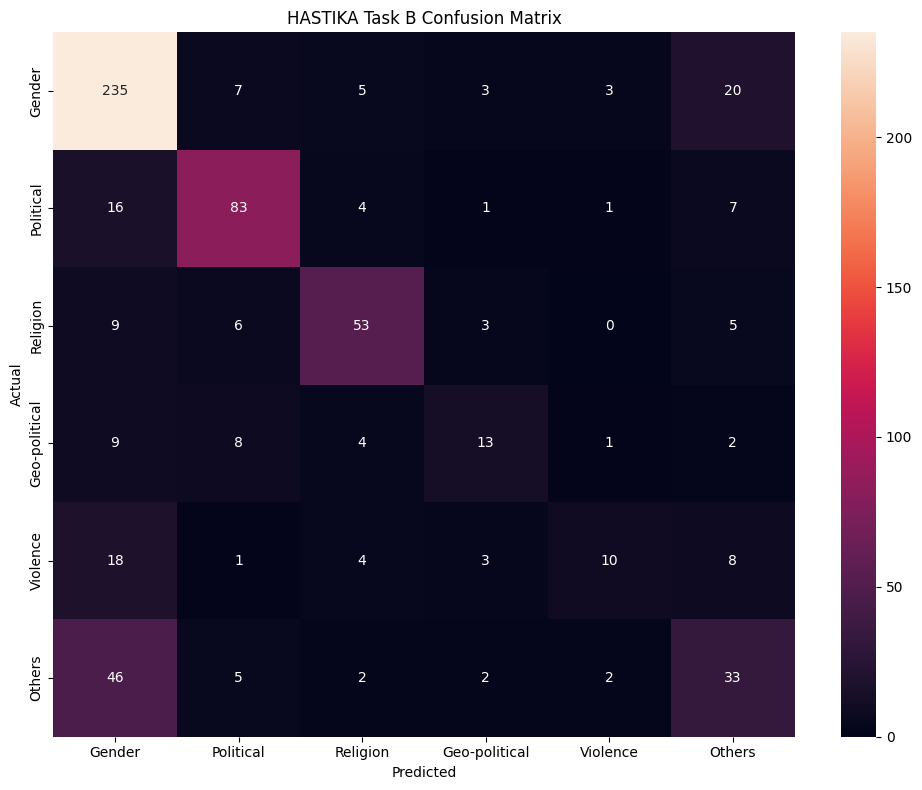

In [65]:
cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=list(range(6))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        id_to_label[i]
        for i in range(6)
    ],
    yticklabels=[
        id_to_label[i]
        for i in range(6)
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("HASTIKA Task B Confusion Matrix")

plt.tight_layout()
plt.show()

In [66]:
val_results = pd.DataFrame({
    "text": X_val.values,
    "true_id": y_val.values,
    "pred_id": val_predictions
})

val_results["true_label"] = (
    val_results["true_id"]
    .map(id_to_label)
)

val_results["pred_label"] = (
    val_results["pred_id"]
    .map(id_to_label)
)

val_results["correct"] = (
    val_results["true_id"]
    ==
    val_results["pred_id"]
)

errors = val_results[
    ~val_results["correct"]
].copy()

print(
    "Validation examples:",
    len(val_results)
)

print(
    "Errors:",
    len(errors)
)

print(
    "Error rate:",
    len(errors) / len(val_results)
)

Validation examples: 632
Errors: 205
Error rate: 0.32436708860759494


In [67]:
display(
    errors[
        [
            "text",
            "true_label",
            "pred_label"
        ]
    ].head(50)
)

,text,true_label,pred_label
5,"Kumkuma, nimma devara photo Ella tegiri.",Religion,Gender
6,Nirilde idre uche hoyyoda iva yentha vakeela s...,Gender,Political
9,"Le hogale muchicondu ello biharinava irbeku, h...",Geo-political,Gender
15,English bere edhuke Kannada ne netuge baralla ...,Others,Gender
16,kannada Jana are poor and enu buddhi illa kach...,Violence,Gender
17,"Le mudiya baadu thindu malakko hogu, saabara t...",Religion,Gender
22,Mujahidin nanmaklanna naduraodnalli shoot madbeku,Religion,Gender
26,Tagalrappa avattu jaggesh avr athra hogi ksham...,Others,Gender
31,Next week sonuna eliminate madi yaru esta padalla,Others,Geo-political
36,Sede thulee king du thap idu...nav king kade n...,Others,Gender


In [68]:
emoji_modes = [
    "keep",
    "demojize",
    "remove"
]

emoji_experiments = []

for mode in emoji_modes:

    print("\n" + "=" * 60)
    print("Testing emoji mode:", mode)
    print("=" * 60)

    X_train_mode = X_train.apply(
        lambda x: normalize_text(
            x,
            emoji_mode=mode
        )
    )

    X_val_mode = X_val.apply(
        lambda x: normalize_text(
            x,
            emoji_mode=mode
        )
    )

    word_vec = TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=100000,
        sublinear_tf=True
    )

    char_vec = TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 6),
        min_df=2,
        max_features=150000,
        sublinear_tf=True
    )

    Xtr_word = word_vec.fit_transform(
        X_train_mode
    )

    Xv_word = word_vec.transform(
        X_val_mode
    )

    Xtr_char = char_vec.fit_transform(
        X_train_mode
    )

    Xv_char = char_vec.transform(
        X_val_mode
    )

    Xtr = hstack([
        Xtr_word,
        Xtr_char
    ])

    Xv = hstack([
        Xv_word,
        Xv_char
    ])

    model = LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42
    )

    model.fit(
        Xtr,
        y_train
    )

    pred = model.predict(Xv)

    score = f1_score(
        y_val,
        pred,
        average="macro",
        zero_division=0
    )

    emoji_experiments.append({
        "emoji_mode": mode,
        "macro_f1": score
    })

emoji_results = pd.DataFrame(
    emoji_experiments
)

display(
    emoji_results.sort_values(
        "macro_f1",
        ascending=False
    )
)


Testing emoji mode: keep

Testing emoji mode: demojize

Testing emoji mode: remove


,emoji_mode,macro_f1
2,remove,0.580867
0,keep,0.579175
1,demojize,0.572004


In [69]:
C_values = [
    0.05,
    0.1,
    0.25,
    0.5,
    0.75,
    1.0,
    1.5,
    2.0,
    3.0,
    5.0,
    7.5,
    10.0
]

tuning_results = []

for C in C_values:

    model = LinearSVC(
        C=C,
        class_weight=TASK_B_CLASS_WEIGHTS,
        random_state=42
    )

    model.fit(
        X_train_combined,
        y_train
    )

    pred = model.predict(
        X_val_combined
    )

    score = f1_score(
        y_val,
        pred,
        average="macro",
        zero_division=0
    )

    tuning_results.append({
        "C": C,
        "macro_f1": score
    })

tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        "macro_f1",
        ascending=False
    )
)

,C,macro_f1
2,0.25,0.581679
3,0.50,0.567985
5,1.00,0.564461
4,0.75,0.562976
6,1.50,0.562332
7,2.00,0.553533
8,3.00,0.552425
10,7.50,0.552421
11,10.00,0.551595
9,5.00,0.551101


In [70]:
best_C = tuning_df.loc[
    tuning_df["macro_f1"].idxmax(),
    "C"
]

print("Best C:", best_C)

Best C: 0.25


In [72]:
FINAL_EMOJI_MODE = "keep"

X_full = train_df["norm_text"].apply(
    lambda x: normalize_text(
        x,
        emoji_mode=FINAL_EMOJI_MODE
    )
)

y_full = train_df["label_id"]

X_test_final = test_df["norm_text"].apply(
    lambda x: normalize_text(
        x,
        emoji_mode=FINAL_EMOJI_MODE
    )
)

print("Full training:", len(X_full))
print("Test:", len(X_test_final))

Full training: 3159
Test: 395


In [73]:
final_word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_features=100000,
    sublinear_tf=True
)

final_char_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 6),
    min_df=2,
    max_features=150000,
    sublinear_tf=True
)

X_full_word = final_word_vectorizer.fit_transform(
    X_full
)

X_test_word = final_word_vectorizer.transform(
    X_test_final
)

X_full_char = final_char_vectorizer.fit_transform(
    X_full
)

X_test_char = final_char_vectorizer.transform(
    X_test_final
)

X_full_combined = hstack([
    X_full_word,
    X_full_char
])

X_test_combined = hstack([
    X_test_word,
    X_test_char
])

print(
    "Full training shape:",
    X_full_combined.shape
)

print(
    "Test shape:",
    X_test_combined.shape
)

Full training shape: (3159, 92991)
Test shape: (395, 92991)


In [74]:
final_task_b_model = LinearSVC(
    C=float(best_C),
    class_weight="balanced",
    random_state=42
)

final_task_b_model.fit(
    X_full_combined,
    y_full
)

print("✅ Final Task B model trained on all training data.")

✅ Final Task B model trained on all training data.


In [75]:
test_predictions_b = final_task_b_model.predict(
    X_test_combined
)

print(
    "Numeric predictions:"
)

print(
    test_predictions_b[:20]
)

Numeric predictions:
[1 5 0 0 5 5 0 0 0 2 2 0 0 0 5 0 0 0 0 0]


In [76]:
test_labels_b = pd.Series(
    test_predictions_b
).map(id_to_label)

print(
    test_labels_b.head(20)
)

0     Political
1        Others
2        Gender
3        Gender
4        Others
5        Others
6        Gender
7        Gender
8        Gender
9      Religion
10     Religion
11       Gender
12       Gender
13       Gender
14       Others
15       Gender
16       Gender
17       Gender
18       Gender
19       Gender
dtype: object


In [77]:
submission_b = pd.DataFrame({
    "id": test_df[ID_COL].values,
    "label": test_labels_b.values
})

print("=" * 60)
print("TASK B SUBMISSION")
print("=" * 60)

print("Shape:", submission_b.shape)

print("\nColumns:")
print(submission_b.columns.tolist())

print("\nLabel distribution:")
print(
    submission_b["label"].value_counts()
)

print("\nFirst 20 rows:")
display(
    submission_b.head(20)
)

TASK B SUBMISSION
Shape: (395, 2)

Columns:
['id', 'label']

Label distribution:
label
Gender           215
Political         71
Others            47
Religion          37
Geo-political     18
Violence           7
Name: count, dtype: int64

First 20 rows:


,id,label
0,4204,Political
1,6264,Others
2,5274,Gender
3,391,Gender
4,4289,Others
5,2404,Others
6,2513,Gender
7,504,Gender
8,449,Gender
9,2357,Religion


In [78]:
VALID_TASK_B_LABELS = [
    "Gender",
    "Political",
    "Religion",
    "Geo-political",
    "Violence",
    "Others"
]

# Correct columns
assert submission_b.columns.tolist() == [
    "id",
    "label"
]

# Correct number of predictions
assert len(submission_b) == len(test_df)

# IDs must be unchanged
assert submission_b["id"].equals(
    test_df[ID_COL].reset_index(drop=True)
)

# Only official labels
assert submission_b["label"].isin(
    VALID_TASK_B_LABELS
).all()

# No missing values
assert submission_b["label"].notna().all()

print("=" * 60)
print("✅ TASK B SUBMISSION VALIDATION PASSED")
print("=" * 60)

print("Rows:", len(submission_b))
print("Columns:", submission_b.columns.tolist())

print("\nLabels:")
print(
    submission_b["label"].value_counts()
)

✅ TASK B SUBMISSION VALIDATION PASSED
Rows: 395
Columns: ['id', 'label']

Labels:
label
Gender           215
Political         71
Others            47
Religion          37
Geo-political     18
Violence           7
Name: count, dtype: int64


In [79]:
submission_path = "/kaggle/working/predictions.csv"

submission_b.to_csv(
    submission_path,
    index=False,
    encoding="utf-8"
)

print("✅ Saved:")
print(submission_path)

✅ Saved:
/kaggle/working/predictions.csv


In [80]:
check_submission = pd.read_csv(
    submission_path
)

display(
    check_submission.head(20)
)

print(
    check_submission.columns.tolist()
)

print(
    check_submission["label"].value_counts()
)

,id,label
0,4204,Political
1,6264,Others
2,5274,Gender
3,391,Gender
4,4289,Others
5,2404,Others
6,2513,Gender
7,504,Gender
8,449,Gender
9,2357,Religion


['id', 'label']
label
Gender           215
Political         71
Others            47
Religion          37
Geo-political     18
Violence           7
Name: count, dtype: int64


In [ ]:
import zipfile

zip_path = "/kaggle/working/task_b_submission.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    z.write(
        submission_path,
        arcname="predictions.csv"
    )

print("✅ ZIP created:")
print(zip_path)